# Predictive Maintenance Using Machine Learning

## 1. Dataset inspection

The synthetic AI4I 2020 dataset (10,000 observations) is explored, focusing on operating measurements and their association with the `Machine failure` label. This is classification of simulated failure conditions, not forecasting remaining useful life.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("../data/ai4i2020.csv")

print("Dataset dimensions:", df.shape)
display(df.head())


Dataset dimensions: (10000, 14)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [2]:
df.info()

display(df.isna().sum())

display(df.describe())


<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  str    
 2   Type                     10000 non-null  str    
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9), str(2)
me

UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


In [3]:
failure_counts = df["Machine failure"].value_counts()
failure_percentages = df["Machine failure"].value_counts(normalize=True) * 100

print("Failure counts:")
print(failure_counts)

print("\nFailure percentages:")
print(failure_percentages.round(2))


Failure counts:
Machine failure
0    9661
1     339
Name: count, dtype: int64

Failure percentages:
Machine failure
0    96.61
1     3.39
Name: proportion, dtype: float64


## 2. Exploratory Data Analysis

The relationship between operating conditions and machine failure is investigated to identify potentially useful predictive features.

In [4]:
features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

# Compare operating conditions between failed and non-failed machines
grouped_stats = df.groupby("Machine failure")[features].mean()

display(grouped_stats.T.round(2))


Machine failure,0,1
Air temperature [K],299.97,300.89
Process temperature [K],310.00,310.29
Rotational speed [rpm],1540.26,1496.49
Torque [Nm],39.63,50.17
Tool wear [min],106.69,143.78


In [10]:
def plot_failure_rate(df, feature, bins=15):
    intervals = pd.cut(df[feature], bins=bins)

    analysis = df.groupby(
        intervals, observed=True
    )["Machine failure"].agg(["mean", "count"])

    analysis["failure_rate"] = analysis["mean"] * 100

    fig, ax = plt.subplots(figsize=(9, 4))

    ax.bar(
        range(len(analysis)),
        analysis["failure_rate"]
    )

    ax.set_xticks(range(len(analysis)))
    ax.set_xticklabels(
        [f"{interval.mid:.1f}" for interval in analysis.index],
        rotation=45
    )

    ax.set_xlabel(feature)
    ax.set_ylabel("Failure rate (%)")
    ax.set_title(f"Machine Failure Rate by {feature}")

    plt.tight_layout()
    plt.show()

    return analysis


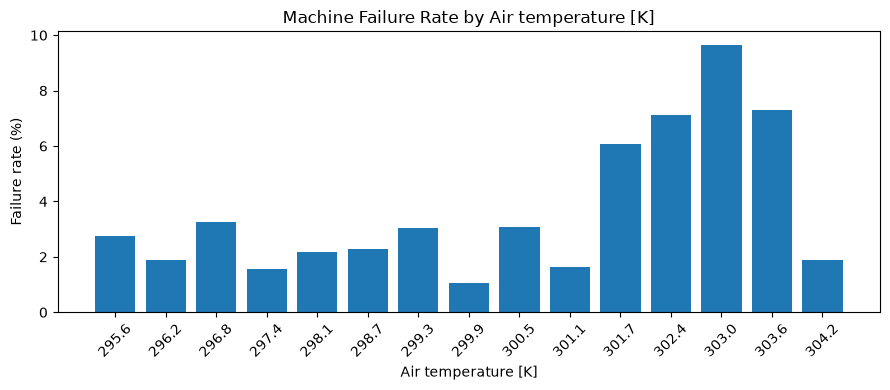

,mean,count,failure_rate
Air temperature [K],,,
"(295.291, 295.913]",0.027523,109,2.752294
"(295.913, 296.527]",0.018868,106,1.886792
"(296.527, 297.14]",0.032544,338,3.254438
"(297.14, 297.753]",0.015740,953,1.573977
"(297.753, 298.367]",0.021739,1012,2.173913
"(298.367, 298.98]",0.022879,1049,2.287893
"(298.98, 299.593]",0.030303,792,3.030303
"(299.593, 300.207]",0.010638,940,1.063830
"(300.207, 300.82]",0.030628,1306,3.062787


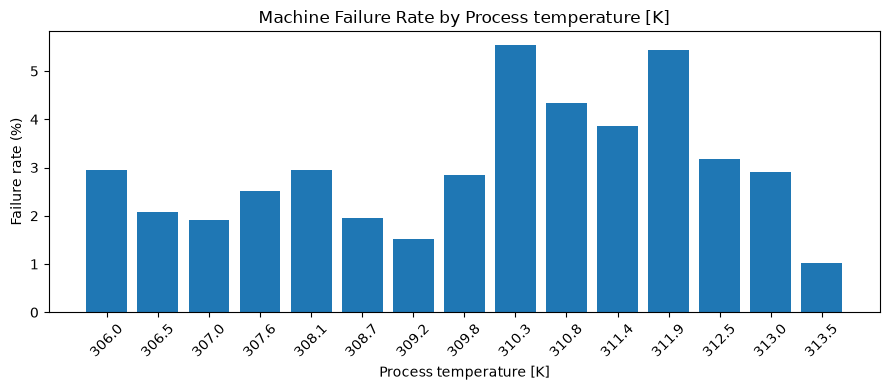

,mean,count,failure_rate
Process temperature [K],,,
"(305.692, 306.24]",0.029412,68,2.941176
"(306.24, 306.78]",0.020833,48,2.083333
"(306.78, 307.32]",0.019048,105,1.904762
"(307.32, 307.86]",0.025057,439,2.505695
"(307.86, 308.4]",0.029412,986,2.941176
"(308.4, 308.94]",0.019571,1073,1.957130
"(308.94, 309.48]",0.015282,1047,1.528176
"(309.48, 310.02]",0.028404,1197,2.840434
"(310.02, 310.56]",0.055461,1172,5.546075


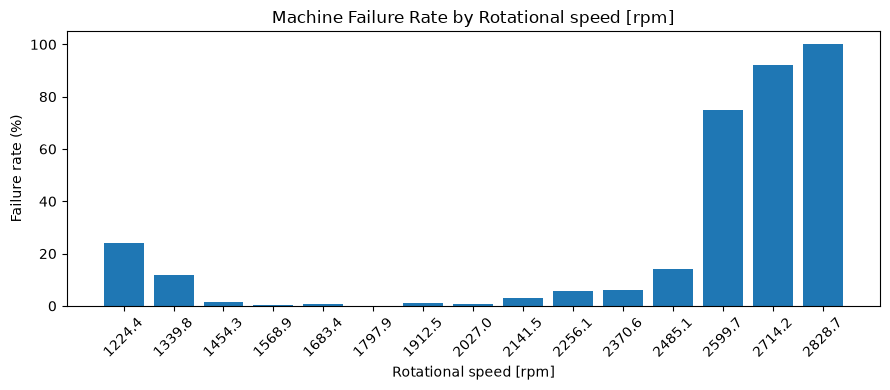

,mean,count,failure_rate
Rotational speed [rpm],,,
"(1166.282, 1282.533]",0.240000,125,24.000000
"(1282.533, 1397.067]",0.120072,1674,12.007168
"(1397.067, 1511.6]",0.014480,3453,1.448016
"(1511.6, 1626.133]",0.004835,2482,0.483481
"(1626.133, 1740.667]",0.007311,1231,0.731113
"(1740.667, 1855.2]",0.000000,501,0.000000
"(1855.2, 1969.733]",0.011583,259,1.158301
"(1969.733, 2084.267]",0.008696,115,0.869565
"(2084.267, 2198.8]",0.031250,64,3.125000


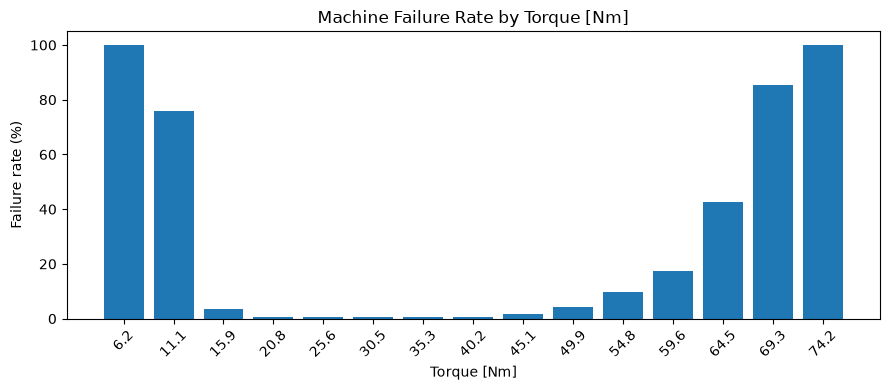

,mean,count,failure_rate
Torque [Nm],,,
"(3.727, 8.653]",1.000000,6,100.000000
"(8.653, 13.507]",0.758621,29,75.862069
"(13.507, 18.36]",0.034783,115,3.478261
"(18.36, 23.213]",0.006024,332,0.602410
"(23.213, 28.067]",0.007407,675,0.740741
"(28.067, 32.92]",0.006284,1273,0.628437
"(32.92, 37.773]",0.005974,1674,0.597372
"(37.773, 42.627]",0.005805,1895,0.580475
"(42.627, 47.48]",0.017391,1725,1.739130


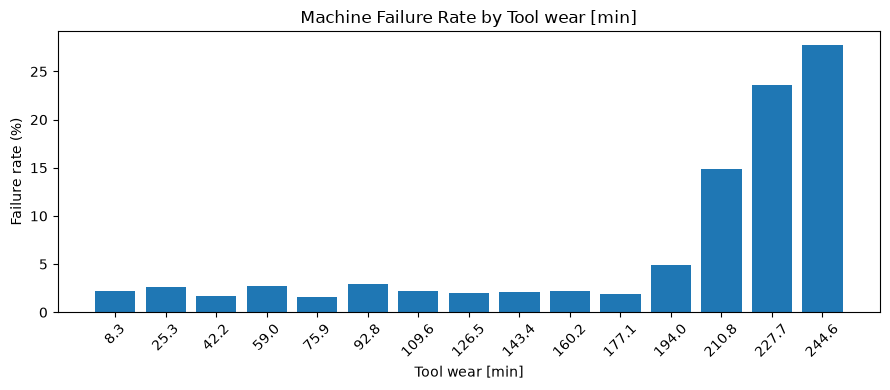

,mean,count,failure_rate
Tool wear [min],,,
"(-0.253, 16.867]",0.021635,832,2.163462
"(16.867, 33.733]",0.026515,792,2.651515
"(33.733, 50.6]",0.016839,772,1.683938
"(50.6, 67.467]",0.027132,774,2.713178
"(67.467, 84.333]",0.015564,771,1.556420
"(84.333, 101.2]",0.029716,774,2.971576
"(101.2, 118.067]",0.021935,775,2.193548
"(118.067, 134.933]",0.020520,731,2.051984
"(134.933, 151.8]",0.020539,779,2.053915


In [13]:
features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

failure_rate_results = {}

for feature in features:
    failure_rate_results[feature] = plot_failure_rate(df, feature)
    display(failure_rate_results[feature])

### Initial Findings

The analysis identifies several relationships between operating conditions and machine failure.

- Torque: Failure rates are elevated at both low and high torque values, suggesting a non-linear relationship.
- Rotational speed: Failure rates increase at certain extreme rotational speeds, although some intervals contain very few observations.
- Tool wear: Failure rates rise substantially at higher levels of tool wear, suggesting a possible threshold-like relationship.
- Temperature: Average temperatures differ relatively little between failed and non-failed observations, although more complex relationships may exist.

These findings suggest that non-linear models may be useful for identifying combinations of operating conditions associated with machine failure.

However, failure rates in sparsely populated intervals should be interpreted cautiously, as a small number of observations can produce unusually high percentages.



## Exploratory Analysis Findings

The exploratory analysis identifies several relationships between operating conditions and machine failure:

- Torque: Failure rates are elevated at both low and high torque values, suggesting a non-linear relationship rather than a consistent increase in failure risk with torque.

- Rotational speed: Failure rates are similarly elevated at unusually low and high rotational speeds. The highest-speed intervals show failure rates of approximately 75–100%, although these intervals contain only 5–13 observations each.

- Tool wear: Failure rates remain relatively low across much of the observed range before increasing substantially at higher levels of tool wear. For example, failure rates rise from approximately 2% at 169–186 minutes to 15% at 202–219 minutes, with both intervals containing more than 500 observations.

- Temperature: Average air and process temperatures differ relatively little between failed and non-failed observations. However, this does not exclude more complex relationships or interactions with other operating conditions.

### Sample Size and Reliability

The reliability of observed failure rates depends heavily on the number of observations within each interval.

Although the highest rotational-speed intervals exhibit exceptionally high failure rates, their small sample sizes limit the statistical reliability of these estimates. A small number of failures can produce disproportionately high percentages.

In contrast, the increase in failure rate at higher tool wear is supported by considerably larger sample sizes, providing stronger evidence of an association between tool wear and machine failure.

These differences highlight the importance of considering sample size alongside observed failure rates when interpreting exploratory results.

### Interpretation and Implications for Modelling

Overall, the findings suggest that machine failure is associated with potentially non-linear relationships and interactions between operating conditions. Models capable of representing such relationships, including Decision Trees and Random Forests, may therefore be particularly suitable for this classification problem.

However, the observed associations do not necessarily imply causation, and extreme failure rates based on small samples should be interpreted cautiously.

The next stage of the project investigates whether these operating measurements can be used to classify machine failures using supervised machine learning.
